# Guía 5 — Parte I: Tiempo retardado y estructura del campo de Liénard–Wiechert

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Problemas **1–3** de la Guía 5. Todo parte de las relaciones (1)–(2) de la guía:

$$\mathbf{R}=\mathbf{r}-\mathbf{r}_q(t_r),\qquad t-t_r=\frac{R(t_r)}{c},\qquad \kappa=1-\hat{n}\cdot\boldsymbol\beta,\qquad
\mathbf{E}_{\rm rad}=\frac{q}{4\pi\varepsilon_0c}\left[\frac{\hat{n}\times[(\hat{n}-\boldsymbol\beta)\times\dot{\boldsymbol\beta}]}{\kappa^3R}\right]_{\rm ret}.$$

| Problema | Simulación | Idea central |
|---|---|---|
| 1 | Diagrama espacio-tiempo de las señales; solución numérica vs. analítica de $t_r$; $dt/dt_r=\kappa$ | El observador "comprime" o "estira" la historia de la fuente |
| 2 | Campos de velocidad ($R^{-2}$) y de radiación ($R^{-1}$); flujo de Poynting por esferas de radio creciente; construcción de Purcell (animación) | Solo el término $R^{-1}$ lleva energía al infinito |
| 3 | $\mathbf{E}_{\rm rad}$, $\mathbf{B}_{\rm rad}$, $\mathbf{S}$ sobre toda la esfera para $\mathbf{a}=a_0\hat{z}$ | El campo de radiación es transversal; $\mathbf{S}$ no depende del signo de $q$ |

**Unidades:** $c=1$ y $q/4\pi\varepsilon_0=1$, de modo que $\varepsilon_0=1/4\pi$, $\mathbf{S}=\frac1{4\pi}\mathbf{E}\times\mathbf{B}$ y Larmor queda $P=\frac23a^2$. Las funciones de Liénard–Wiechert están en `../em_utils.py`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

import em_utils as u
u.estilo()
C = u.COLORES

def trayectoria(w, v, a):
    # envuelve funciones escalares x(t) -> (3,) para que acepten arreglos de t_r
    def env(f):
        return lambda t: np.asarray(f(np.asarray(t, float)), float)
    return env(w), env(v), env(a)

---
## Problema 1 — Tiempo retardado de una carga en movimiento uniforme

Carga en $\mathbf{r}_q=vt\,\hat{z}$ y observador en $Z\hat{z}$, con la carga todavía detrás de él ($Z>vt_r$). La condición de retardo es

$$t-t_r=\frac{Z-vt_r}{c}\;\Longrightarrow\;t_r(1-\beta)=t-\frac Zc\;\Longrightarrow\;\boxed{t_r=\frac{t-Z/c}{1-\beta}},\qquad \frac{dt}{dt_r}=1-\beta=\kappa .$$

**Interpretación.** Dos señales emitidas con separación $\Delta t_r$ llegan separadas por $\Delta t=(1-\beta)\Delta t_r$. La segunda señal sale más cerca del observador y viaja menos. El observador ve la historia de la fuente **comprimida** si esta se acerca ($\hat{n}\cdot\boldsymbol\beta>0$) y **estirada** si se aleja. Ese es el origen cinemático del efecto Doppler y del factor $\kappa$ en los campos.

Primero comparamos la fórmula con el solucionador numérico general de `em_utils` (bisección sobre el cono de luz pasado). El solucionador no sabe de qué lado está la carga. Cuando ya pasó al observador, la condición cambia a $t-t_r=(vt_r-Z)/c$ y da $t_r=(t+Z/c)/(1+\beta)$: ahora la carga se **aleja** y $dt/dt_r=1+\beta$.

In [2]:
Z = 10.0
print("  β      t     t_r numérico      t_r analítico     ¿carga detrás del observador en t_r?")
for beta in [0.2, 0.6, 0.9]:
    w, v, a = trayectoria(lambda t: np.stack([0*t, 0*t, beta*t], -1),
                          lambda t: np.stack([0*t, 0*t, beta + 0*t], -1),
                          lambda t: np.zeros(np.shape(t) + (3,)))
    for t in [0.0, 5.0, 12.0]:
        tr_num = u.tiempo_retardado(np.array([[0, 0, Z]]), t, w)[0]
        tr_an = (t - Z)/(1 - beta)                  # válido si la carga está detrás: β t_r < Z
        detras = beta*tr_an < Z
        if not detras:
            tr_an = (t + Z)/(1 + beta)              # la carga ya pasó: t - t_r = (v t_r - Z)/c
        print(f" {beta:.1f}  {t:5.1f}   {tr_num:12.8f}    {tr_an:12.8f}      {'sí' if detras else 'no (ya pasó: t_r=(t+Z/c)/(1+β))'}")

  β      t     t_r numérico      t_r analítico     ¿carga detrás del observador en t_r?
 0.2    0.0   -12.50000000    -12.50000000      sí
 0.2    5.0    -6.25000000     -6.25000000      sí
 0.2   12.0     2.50000000      2.50000000      sí
 0.6    0.0   -25.00000000    -25.00000000      sí
 0.6    5.0   -12.50000000    -12.50000000      sí
 0.6   12.0     5.00000000      5.00000000      sí
 0.9    0.0   -100.00000000    -100.00000000      sí
 0.9    5.0   -50.00000000    -50.00000000      sí
 0.9   12.0    11.57894737     11.57894737      no (ya pasó: t_r=(t+Z/c)/(1+β))


[guardado] figuras/P1_espaciotiempo_tiempo_retardado.png


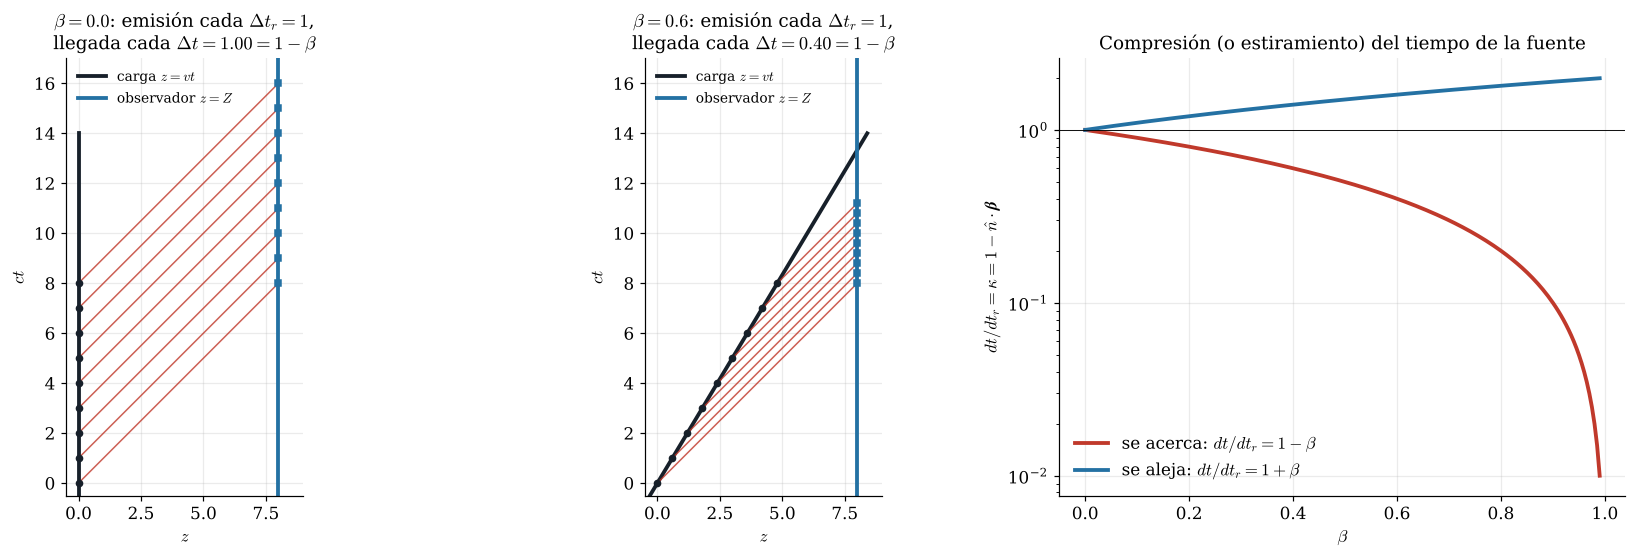

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
for A, beta in zip(ax[:2], [0.0, 0.6]):
    Z = 8.0
    t_emis = np.arange(0, 9, 1.0)                      # emisiones a intervalos Δt_r = 1
    ts = np.linspace(-1, 14, 100)
    A.plot(beta*ts, ts, color=C['carga'], lw=2.5, label='carga $z=vt$')
    A.axvline(Z, color=C['B'], lw=2.5, label='observador $z=Z$')
    llegadas = []
    for te in t_emis:
        ze = beta*te
        if ze >= Z:
            continue
        tl = te + (Z - ze)                              # c = 1
        llegadas.append(tl)
        A.plot([ze, Z], [te, tl], color=C['E'], lw=1, alpha=0.8)
        A.plot(ze, te, 'o', color=C['carga'], ms=4); A.plot(Z, tl, 's', color=C['B'], ms=4)
    A.set_xlim(-0.5, 9); A.set_ylim(-0.5, 17); A.set_aspect('equal')
    A.set_xlabel('$z$'); A.set_ylabel('$ct$')
    dl = np.diff(llegadas).mean()
    A.set_title(f'$\\beta={beta}$: emisión cada $\\Delta t_r=1$,\nllegada cada $\\Delta t={dl:.2f}=1-\\beta$')
    A.legend(loc='upper left', fontsize=9)
A = ax[2]
bb = np.linspace(0, 0.99, 200)
A.semilogy(bb, 1 - bb, color=C['E'], lw=2.5, label=r'se acerca: $dt/dt_r=1-\beta$')
A.semilogy(bb, 1 + bb, color=C['B'], lw=2.5, label=r'se aleja: $dt/dt_r=1+\beta$')
A.axhline(1, color='k', lw=0.6)
A.set_xlabel(r'$\beta$'); A.set_ylabel(r'$dt/dt_r=\kappa=1-\hat{n}\cdot\boldsymbol{\beta}$')
A.set_title('Compresión (o estiramiento) del tiempo de la fuente'); A.legend()
fig.tight_layout(); u.guardar(fig, 'P1_espaciotiempo_tiempo_retardado'); plt.show()

**(c) ¿Hay radiación?** Con $\mathbf{v}$ constante, $\dot{\boldsymbol\beta}=0$ y el término radiativo de (2) es **idénticamente nulo**. Solo queda el campo de velocidad, que decae como $R^{-2}$, igual que Coulomb. Lo verificamos más abajo junto con el Problema 2: para la carga uniforme, $R^2|\mathbf{E}|^2\to0$.

---
## Problema 2 — Campos de velocidad y de radiación

$$\mathbf{E}=\underbrace{\frac{q}{4\pi\varepsilon_0}\frac{(\hat{n}-\boldsymbol\beta)(1-\beta^2)}{\kappa^3R^2}}_{\mathbf{E}_{\rm vel}\;\propto\;R^{-2}}+\underbrace{\frac{q}{4\pi\varepsilon_0c}\frac{\hat{n}\times[(\hat{n}-\boldsymbol\beta)\times\dot{\boldsymbol\beta}]}{\kappa^3R}}_{\mathbf{E}_{\rm rad}\;\propto\;R^{-1}} .$$

### Escalamiento a lo largo de un rayo

Si se duplica la distancia, $E_{\rm vel}$ cae a $1/4$ y $E_{\rm rad}$ a $1/2$. Por eso $R^2E^2$, proporcional a la potencia por ángulo sólido, va como $R^{-2}$ para el término de velocidad y es **constante** para el de radiación.

Usamos una carga que oscila lentamente, $z_q=A\sin\omega t$ con $\beta_{\max}=A\omega=0.05$, y una carga uniforme como referencia. Medimos los valores cuadráticos medios (sobre un período) en el ecuador.

máx |E_rad| para la carga uniforme: 0.0


[guardado] figuras/P2_escalamiento_campos_vel_rad.png


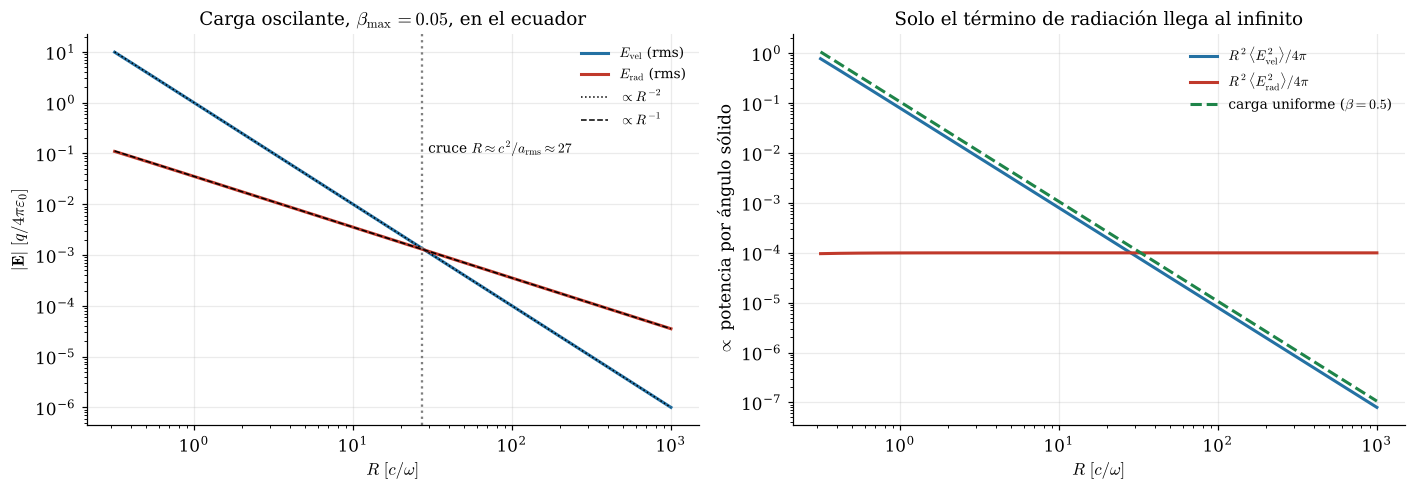

In [4]:
A_osc, om = 0.05, 1.0                       # beta_max = 0.05, lambda = 2π
w_o, v_o, a_o = trayectoria(lambda t: np.stack([0*t, 0*t, A_osc*np.sin(om*t)], -1),
                            lambda t: np.stack([0*t, 0*t, A_osc*om*np.cos(om*t)], -1),
                            lambda t: np.stack([0*t, 0*t, -A_osc*om**2*np.sin(om*t)], -1))
w_u, v_u, a_u = trayectoria(lambda t: np.stack([0*t, 0*t, 0.5*t], -1),
                            lambda t: np.stack([0*t, 0*t, 0.5 + 0*t], -1),
                            lambda t: np.zeros(np.shape(t) + (3,)))

Rs = np.logspace(-0.5, 3, 30)
ts = np.linspace(0, 2*np.pi, 48, endpoint=False)
puntos = np.stack([Rs, 0*Rs, 0*Rs], -1)
Ev2 = np.zeros_like(Rs); Er2 = np.zeros_like(Rs)
for t in ts:
    Ev, Er, _, _ = u.campos_LW(puntos, t, w_o, v_o, a_o)
    Ev2 += np.sum(Ev**2, -1)/len(ts); Er2 += np.sum(Er**2, -1)/len(ts)
# carga uniforme: puntos a distancia R de su posición PRESENTE, en dirección perpendicular a v
t0 = 3.0
pu = np.stack([Rs, 0*Rs, 0.5*t0 + 0*Rs], -1)
Evu, Eru, _, _ = u.campos_LW(pu, t0, w_u, v_u, a_u)
print("máx |E_rad| para la carga uniforme:", np.abs(Eru).max())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
A = ax[0]
A.loglog(Rs, np.sqrt(Ev2), color=C['B'], lw=2, label=r'$E_{\rm vel}$ (rms)')
A.loglog(Rs, np.sqrt(Er2), color=C['E'], lw=2, label=r'$E_{\rm rad}$ (rms)')
A.loglog(Rs, 1/Rs**2, 'k:', lw=1, label=r'$\propto R^{-2}$')
A.loglog(Rs, np.sqrt(Er2)[-1]*Rs[-1]/Rs, 'k--', lw=1, label=r'$\propto R^{-1}$')
Rx = np.sqrt(Ev2/Er2); i = np.argmin(np.abs(np.log(Rx)))
A.axvline(Rs[i], color='0.5', ls=':'); A.text(Rs[i]*1.1, 1e-1, fr'cruce $R\approx c^2/a_{{\rm rms}}\approx{Rs[i]:.0f}$', fontsize=9)
A.set_xlabel(r'$R\;[c/\omega]$'); A.set_ylabel(r'$|\mathbf{E}|\;[q/4\pi\varepsilon_0]$')
A.set_title(r'Carga oscilante, $\beta_{\max}=0.05$, en el ecuador'); A.legend(fontsize=9)
A = ax[1]
A.loglog(Rs, Rs**2*Ev2/(4*np.pi), color=C['B'], lw=2, label=r'$R^2\,\langle E_{\rm vel}^2\rangle/4\pi$')
A.loglog(Rs, Rs**2*Er2/(4*np.pi), color=C['E'], lw=2, label=r'$R^2\,\langle E_{\rm rad}^2\rangle/4\pi$')
A.loglog(Rs, Rs**2*np.sum(Evu**2, -1)/(4*np.pi), color=C['v'], lw=2, ls='--', label=r'carga uniforme ($\beta=0.5$)')
A.set_xlabel(r'$R\;[c/\omega]$'); A.set_ylabel(r'$\propto$ potencia por ángulo sólido')
A.set_title('Solo el término de radiación llega al infinito'); A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P2_escalamiento_campos_vel_rad'); plt.show()

El cruce está en $R\sim c^2/a$, no en $R\sim\lambda$. Una carga lenta tiene un Coulomb "enorme" comparado con su campo de radiación. Aun así, a distancia suficiente gana siempre el término $R^{-1}$.

### Flujo de Poynting a través de esferas

Una afirmación más fuerte: calculamos el flujo **total** $\oint\mathbf{S}\cdot d\mathbf{a}$ por esferas de radio $R$, separando $\mathbf{S}$ en las partes vel–vel, rad–rad y cruzada ($\mathbf{B}=\hat{n}\times\mathbf{E}/c$ con el $\hat{n}$ retardado), y promediamos sobre un período.

- La parte rad–rad da la potencia de Larmor, $\langle P\rangle=\frac23\langle a^2\rangle=\frac13A^2\omega^4$, **para cualquier $R$**.
- Las partes vel–vel y cruzada pueden ser enormes en cada instante cerca de la carga, pero su promedio es nulo. Es energía **reactiva**, que va y vuelve sin escapar.

 R        <Φ_rr>/P_L   <Φ_vv+Φ_cr>/P_L   rms(Φ_vv+Φ_cr)/P_L
   0.32      1.0019       +0.00e+00       2.55e+01
   0.56      1.0019       +0.00e+00       5.72e+00
   1.00      1.0019       +0.00e+00       1.88e+00
   1.78      1.0019       +0.00e+00       8.67e-01
   3.16      1.0019       +0.00e+00       4.60e-01
   5.62      1.0019       +1.22e-17       2.54e-01
  10.00      1.0019       -1.22e-17       1.42e-01
  17.78      1.0019       -1.02e-17       7.98e-02
  31.62      1.0019       -7.37e-18       4.48e-02
  56.23      1.0019       -9.47e-18       2.52e-02
 100.00      1.0019       +7.13e-18       1.42e-02
 177.83      1.0019       -9.92e-18       7.97e-03
 316.23      1.0019       -2.46e-19       4.48e-03
[guardado] figuras/P2_flujo_poynting_esferas.png


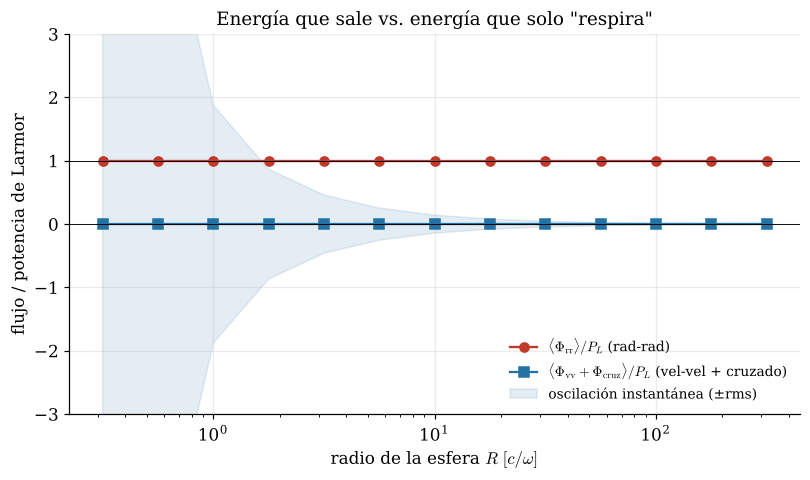

In [5]:
mu, wmu = np.polynomial.legendre.leggauss(64)      # simetría azimutal: basta un meridiano
Rs2 = np.logspace(-0.5, 2.5, 13)
tt = np.linspace(0, 2*np.pi, 64, endpoint=False)
P_L = A_osc**2*om**4/3
res = []
for R in Rs2:
    pts = R*np.stack([np.sqrt(1 - mu**2), 0*mu, mu], -1)
    nrm = pts/R
    fl = {'vv': [], 'rr': [], 'cr': []}
    for t in tt:
        Ev, Er, _, trr = u.campos_LW(pts, t, w_o, v_o, a_o)
        nret = pts - w_o(trr); nret /= np.linalg.norm(nret, axis=-1, keepdims=True)
        Bv, Br = np.cross(nret, Ev), np.cross(nret, Er)
        flujo = lambda E_, B_: 2*np.pi*R**2*np.sum(wmu*np.sum(np.cross(E_, B_)*nrm, -1))/(4*np.pi)
        fl['vv'].append(flujo(Ev, Bv)); fl['rr'].append(flujo(Er, Br))
        fl['cr'].append(flujo(Ev, Br) + flujo(Er, Bv))
    res.append({k: (np.mean(val), np.std(val)) for k, val in fl.items()})

print(" R        <Φ_rr>/P_L   <Φ_vv+Φ_cr>/P_L   rms(Φ_vv+Φ_cr)/P_L")
for R, r_ in zip(Rs2, res):
    print(f"{R:7.2f}   {r_['rr'][0]/P_L:9.4f}    {(r_['vv'][0] + r_['cr'][0])/P_L:+12.2e}     {np.hypot(r_['vv'][1], r_['cr'][1])/P_L:10.2e}")

fig, A = plt.subplots(figsize=(7.5, 4.5))
A.semilogx(Rs2, [r_['rr'][0]/P_L for r_ in res], 'o-', color=C['E'], label=r'$\langle\Phi_{\rm rr}\rangle/P_L$ (rad-rad)')
A.semilogx(Rs2, [(r_['vv'][0] + r_['cr'][0])/P_L for r_ in res], 's-', color=C['B'], label=r'$\langle\Phi_{\rm vv}+\Phi_{\rm cruz}\rangle/P_L$ (vel-vel + cruzado)')
A.fill_between(Rs2, [-np.hypot(r_['vv'][1], r_['cr'][1])/P_L for r_ in res],
               [np.hypot(r_['vv'][1], r_['cr'][1])/P_L for r_ in res], color=C['B'], alpha=0.12,
               label='oscilación instantánea (±rms)')
A.set_ylim(-3, 3); A.axhline(1, color='k', lw=0.6); A.axhline(0, color='k', lw=0.6)
A.set_xlabel(r'radio de la esfera $R\;[c/\omega]$'); A.set_ylabel(r'flujo / potencia de Larmor')
A.set_title('Energía que sale vs. energía que solo "respira"'); A.legend(fontsize=9, loc='lower right')
fig.tight_layout(); u.guardar(fig, 'P2_flujo_poynting_esferas'); plt.show()

La pequeña diferencia de $\langle\Phi_{\rm rr}\rangle/P_L$ respecto de 1 es de orden $\beta^2$: es la corrección relativista de Liénard, $\gamma^6(\cdots)$, para $\beta_{\max}=0.05$.

### Construcción de Purcell: la radiación es un "pliegue" en las líneas de campo

Una carga en reposo en el origen recibe un breve empujón ($a=a_0$ durante $0<t<\tau$) y queda moviéndose con $\beta=0.5$. Calculamos el campo **exacto** de Liénard–Wiechert en una malla y trazamos las líneas de $\mathbf{E}$ desde la posición presente de la carga. La causalidad separa tres regiones:

- **afuera** de la esfera $r=ct$, la información del empujón aún no llega y las líneas siguen saliendo del origen (Coulomb en reposo);
- **adentro** de $r=c(t-\tau)$ está el campo de una carga uniforme (el panqueque de la Guía 6);
- en el **cascarón** intermedio, de espesor $c\tau$, las líneas se doblan para conectar ambas regiones.

Ese pliegue transversal es el campo de radiación. Geométricamente, $E_\perp/E_r\sim(a\sin\theta/c^2)\,R$, y como $E_r\propto R^{-2}$, resulta $E_\perp\propto R^{-1}$.

[guardado] figuras/P2_purcell_lineas_de_campo.png


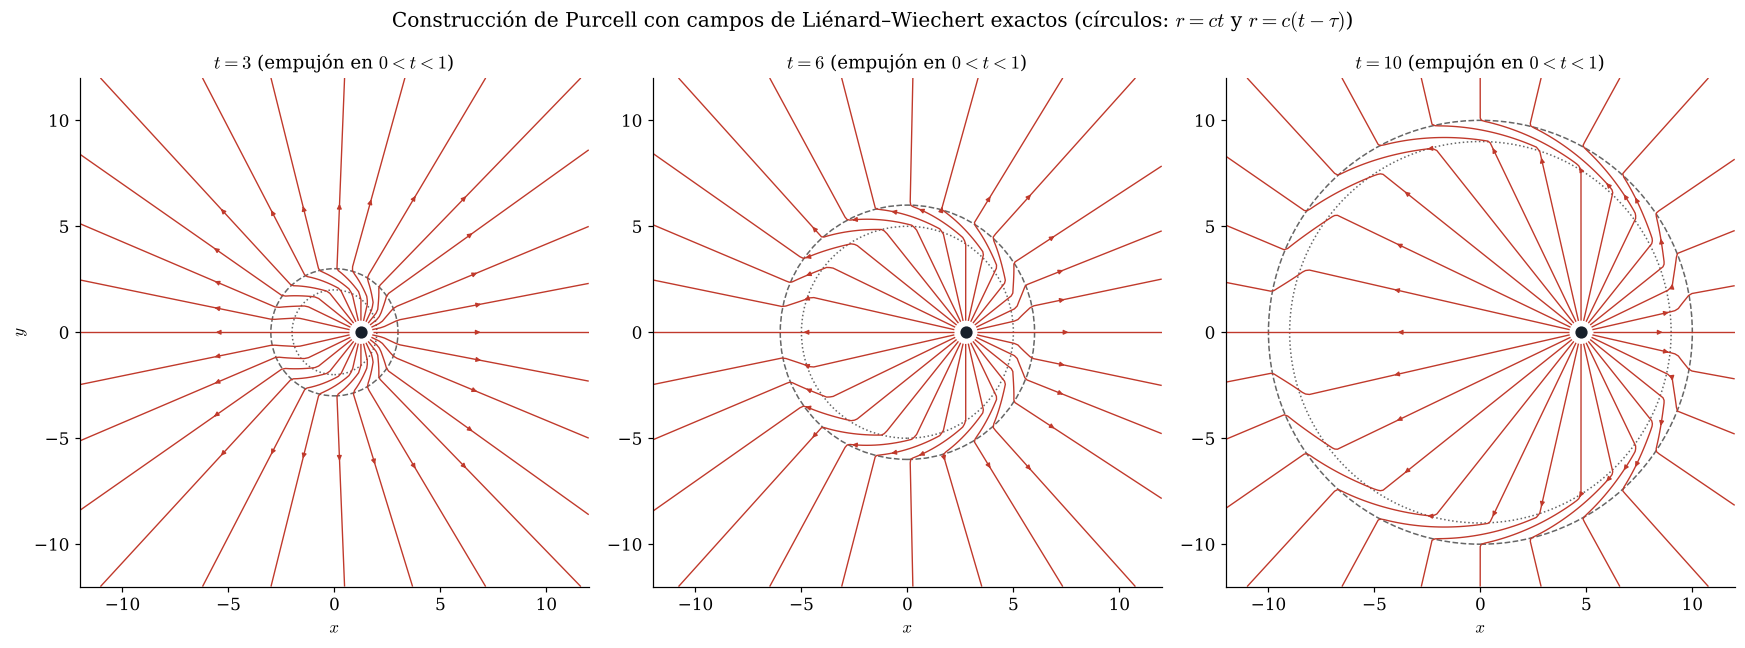

|E_rad| máximo en el cascarón vs. su radio: pendiente log-log = -1.014  (esperado −1)


In [6]:
a0, tau = 0.5, 1.0                                 # beta final = a0*tau = 0.5
def _x(t):  return np.where(t < 0, 0, np.where(t < tau, 0.5*a0*t**2, 0.5*a0*tau**2 + a0*tau*(t - tau)))
def _vx(t): return a0*np.clip(t, 0, tau)
def _ax(t): return np.where((t >= 0) & (t < tau), a0, 0.0)
w_p, v_p, a_p = trayectoria(lambda t: np.stack([_x(t), 0*t, 0*t], -1),
                            lambda t: np.stack([_vx(t), 0*t, 0*t], -1),
                            lambda t: np.stack([_ax(t), 0*t, 0*t], -1))
L, Ng = 12.0, 401
g1 = np.linspace(-L, L, Ng); XX, YY = np.meshgrid(g1, g1)
P = np.stack([XX, YY, 0*XX], -1)

def dibujar_purcell(A, t):
    Ev, Er, _, _ = u.campos_LW(P, t, w_p, v_p, a_p)
    E = Ev + Er
    xq = float(_x(np.array(t)))
    semillas = np.array([[xq + 0.35*np.cos(f), 0.35*np.sin(f)] for f in np.linspace(0, 2*np.pi, 28, endpoint=False)])
    A.streamplot(g1, g1, E[..., 0], E[..., 1], start_points=semillas, color=C['E'], linewidth=0.9,
                 density=4, arrowsize=0.6, integration_direction='forward', broken_streamlines=False)
    for rr, ls in [(t, '--'), (t - tau, ':')]:
        if rr > 0:
            A.add_patch(plt.Circle((0, 0), rr, fill=False, ls=ls, color='0.4', lw=1))
    A.plot(xq, 0, 'o', color=C['carga'], ms=7)
    A.set_xlim(-L, L); A.set_ylim(-L, L); A.set_aspect('equal'); A.grid(False)

fig, ax = plt.subplots(1, 3, figsize=(16, 5.6))
for A, t in zip(ax, [3.0, 6.0, 10.0]):
    dibujar_purcell(A, t); A.set_title(f'$t={t:.0f}$ (empujón en $0<t<{tau:.0f}$)'); A.set_xlabel('$x$')
ax[0].set_ylabel('$y$')
fig.suptitle('Construcción de Purcell con campos de Liénard–Wiechert exactos (círculos: $r=ct$ y $r=c(t-\\tau)$)', y=1.0)
fig.tight_layout(); u.guardar(fig, 'P2_purcell_lineas_de_campo'); plt.show()

# E_rad en el centro del cascarón a lo largo del eje y (θ = 90° respecto de a), para varios tiempos
ts_ = np.array([3, 5, 8, 12, 20, 40.0])
Ecasc = []
for t in ts_:
    rr = np.linspace(t - tau, t, 200); pts = np.stack([0*rr, rr, 0*rr], -1)
    _, Er, _, _ = u.campos_LW(pts, t, w_p, v_p, a_p)
    Ecasc.append(np.linalg.norm(Er, axis=-1).max())
pend = np.polyfit(np.log(ts_ - tau/2), np.log(Ecasc), 1)[0]
print(f"|E_rad| máximo en el cascarón vs. su radio: pendiente log-log = {pend:.3f}  (esperado −1)")

In [7]:
fig, A = plt.subplots(figsize=(5.6, 5.6))
fr = 30
def cuadro(i):
    A.clear(); t = 0.3 + 11.2*i/(fr - 1)
    dibujar_purcell(A, t); A.set_title(f'Construcción de Purcell,  $t={t:.1f}$')
anim = animation.FuncAnimation(fig, cuadro, frames=fr)
u.guardar_gif(anim, 'P2_animacion_purcell', fps=8, dpi=70)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P2_animacion_purcell.gif)

[guardado] figuras/P2_animacion_purcell.gif  (0.68 MB)


![animación](figuras/P2_animacion_purcell.gif)

---
## Problema 3 — Dirección y polarización del campo radiativo

Con $\mathbf{a}=a_0\hat{z}$ (no relativista), $\hat{n}\times(\hat{n}\times\hat{z})=\hat{n}\cos\theta-\hat{z}=\sin\theta\,\hat\theta$. Entonces:

- $\mathbf{E}_{\rm rad}\propto q\,a_0\sin\theta\,\hat\theta/R$ (a lo largo de los **meridianos**);
- $\mathbf{B}_{\rm rad}=\hat{n}\times\mathbf{E}/c\propto q\,a_0\sin\theta\,\hat\phi/R$ (a lo largo de los **paralelos**);
- $\mathbf{S}=\varepsilon_0cE^2\hat{n}\propto q^2\sin^2\theta\,\hat{n}$, radial y **par en $q$**.

Primero los incisos (a) y (b) numéricamente, para $q=\pm1$:

In [8]:
a = np.array([0, 0, 1.0])
for q in (+1, -1):
    for nombre, n in [('x̂', np.array([1.0, 0, 0])), ('ẑ', np.array([0, 0, 1.0]))]:
        E = q*np.cross(n, np.cross(n, a))          # unidades q a0/(4π ε0 c² R)
        B = np.cross(n, E)                          # unidades de E/c
        S = np.cross(E, B)/(4*np.pi)
        print(f"q={q:+d}, n={nombre}:  E = {E},  cB = {B},  S ∝ {S}")

q=+1, n=x̂:  E = [ 0.  0. -1.],  cB = [-0.  1.  0.],  S ∝ [0.07957747 0.         0.        ]
q=+1, n=ẑ:  E = [0. 0. 0.],  cB = [0. 0. 0.],  S ∝ [0. 0. 0.]
q=-1, n=x̂:  E = [-0. -0.  1.],  cB = [ 0. -1.  0.],  S ∝ [0.07957747 0.         0.        ]
q=-1, n=ẑ:  E = [-0. -0. -0.],  cB = [0. 0. 0.],  S ∝ [0. 0. 0.]


[guardado] figuras/P3_campos_en_la_esfera.png


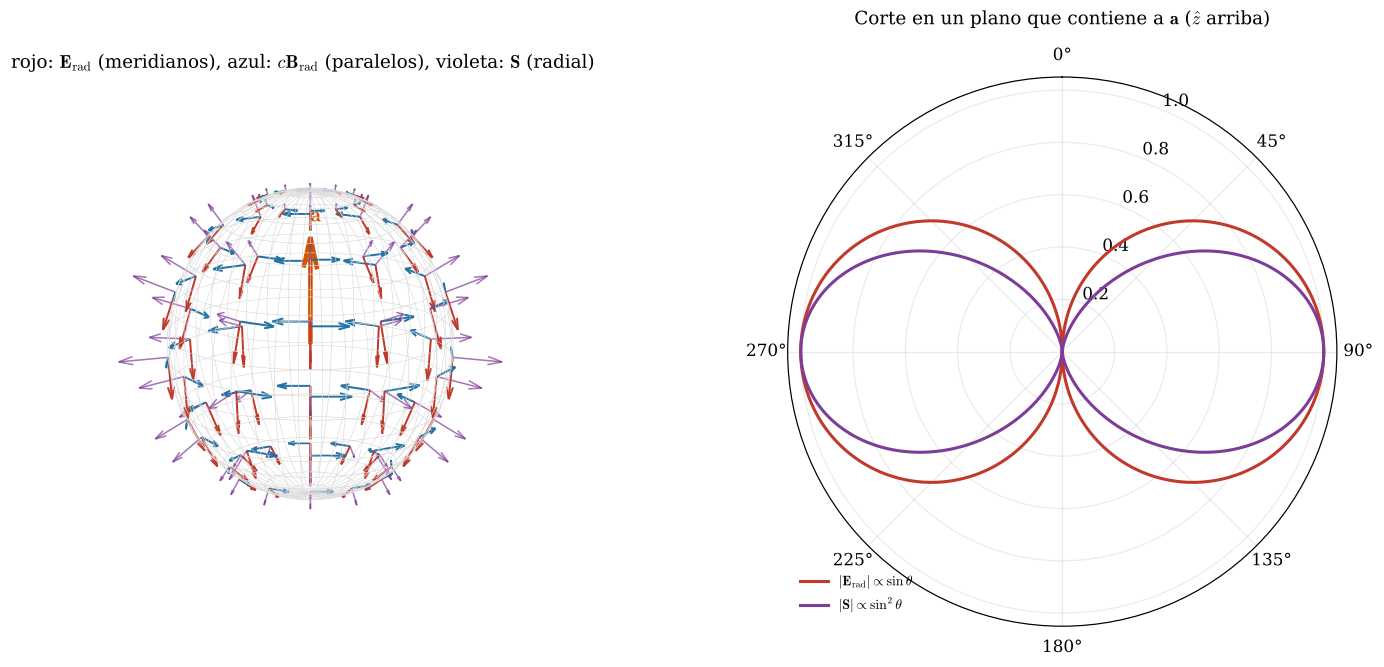

In [9]:
fig = plt.figure(figsize=(14, 6.2))
A = fig.add_subplot(1, 2, 1, projection='3d')
for th in np.radians(np.arange(20, 170, 25)):
    for ph in np.radians(np.arange(0, 360, 30)):
        n = np.array([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)])
        E = np.cross(n, np.cross(n, a)); B = np.cross(n, E)
        A.quiver(*n, *(0.28*E), color=C['E'], lw=1.3, arrow_length_ratio=0.3)
        A.quiver(*n, *(0.28*B), color=C['B'], lw=1.3, arrow_length_ratio=0.3)
        A.quiver(*n, *(0.35*(E @ E)*n), color=C['S'], lw=1.0, arrow_length_ratio=0.3, alpha=0.7)
uu_, vv_ = np.meshgrid(np.linspace(0, 2*np.pi, 40), np.linspace(0, np.pi, 20))
A.plot_wireframe(np.cos(uu_)*np.sin(vv_), np.sin(uu_)*np.sin(vv_), np.cos(vv_), color='0.85', lw=0.4)
A.quiver(0, 0, 0, 0, 0, 0.7, color=C['a'], lw=3); A.text(0, 0, 0.8, r'$\mathbf{a}$', color=C['a'], fontsize=14)
A.set_box_aspect((1, 1, 1)); A.set_axis_off(); A.view_init(elev=15, azim=-60)
A.set_title(r'rojo: $\mathbf{E}_{\rm rad}$ (meridianos), azul: $c\mathbf{B}_{\rm rad}$ (paralelos), violeta: $\mathbf{S}$ (radial)')

A = fig.add_subplot(1, 2, 2, projection='polar')
th = np.linspace(0, 2*np.pi, 400)
A.plot(th, np.abs(np.sin(th)), color=C['E'], lw=2, label=r'$|\mathbf{E}_{\rm rad}|\propto\sin\theta$')
A.plot(th, np.sin(th)**2, color=C['S'], lw=2, label=r'$|\mathbf{S}|\propto\sin^2\theta$')
A.set_theta_zero_location('N'); A.set_theta_direction(-1)
A.set_title(r'Corte en un plano que contiene a $\mathbf{a}$ ($\hat{z}$ arriba)', pad=15); A.legend(loc='lower left', fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P3_campos_en_la_esfera'); plt.show()

**Resumen.** Para $\hat{n}=\hat{x}$: $\mathbf{E}\propto-q a_0\hat{z}$, $c\mathbf{B}\propto+q a_0\hat{y}$ y $\mathbf{S}\propto+\hat{x}$, la dirección de observación. Para $\hat{n}=\hat{z}$ todo se anula: mirando a lo largo de $\mathbf{a}$, la carga no tiene movimiento transversal aparente. Cambiar $q\to-q$ invierte $\mathbf{E}$ y $\mathbf{B}$ a la vez, pero no $\mathbf{S}\propto\mathbf{E}\times\mathbf{B}$: **la energía siempre sale hacia afuera**.